# 📊 Hotel Reservation System: EDA & Business Intelligence

## 📌 Data Understanding & Preparation
**Project:** Enterprise Hotel Reservation System  
**Objective:** To analyze historical booking data to uncover revenue drivers, seasonal trends, and guest behavior, enabling data-driven decision-making for the executive team.

### 🎯 Key Business Questions:
1. Which hotel properties generate the highest revenue?
2. What is the revenue contribution of different room tiers (Standard to Royal Penthouse)?
3. How does seasonality (months/quarters) impact revenue?
4. What is the ratio of Cancelled vs. Confirmed vs. Completed bookings?
5. Do VIP guests (Gold/Platinum/Diamond) spend more per stay?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import warnings

# Suppress warnings for clean output
warnings.filterwarnings('ignore')

# Set professional visualization style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12, 'figure.figsize': (12, 6)})

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


In [ ]:
# with your actual PostgreSQL password
DB_USER = 'postgres'
DB_PASS = 'postgres'  
DB_HOST = 'localhost'
DB_PORT = '5432'
DB_NAME = 'hotel_enterprise'

try:
    engine = create_engine(f'postgresql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}')
    print("✅ Successfully connected to PostgreSQL database.")
except Exception as e:
    print(f"❌ Connection failed: {e}")

✅ Successfully connected to PostgreSQL database.


In [3]:

# Get a list of all tables in the database
tables = pd.read_sql("""
    SELECT table_name 
    FROM information_schema.tables 
    WHERE table_schema = 'public' 
    AND table_type = 'BASE TABLE'
    ORDER BY table_name;
""", engine)

# Loop through each table and display it
for table in tables['table_name']:
    print(f"\n==================================================")
    print(f" TABLE: {table.upper()}")
    print(f"==================================================")
    
    df = pd.read_sql(f"SELECT * FROM {table} LIMIT 5;", engine)
    if df.empty:
        print("(Empty Table)")
    else:
        display(df)


 TABLE: DIM_DATE


,date_key,full_date,year,month,day,quarter,is_weekend
0,20260101,2026-01-01,2026,1,1,1,False
1,20260102,2026-01-02,2026,1,2,1,False
2,20260103,2026-01-03,2026,1,3,1,True
3,20260104,2026-01-04,2026,1,4,1,True
4,20260105,2026-01-05,2026,1,5,1,False



 TABLE: FACILITY
(Empty Table)

 TABLE: FACT_BOOKING


,fact_id,reservation_id,room_id,property_id,date_key,revenue
0,1,1,1,1,20260110,500.0
1,2,12,5,1,20260705,2250.0
2,3,14,6,1,20260801,1200.0
3,4,2,7,1,20260214,1800.0
4,5,17,8,1,20261010,2000.0



 TABLE: GUEST


,person_id,loyalty_points,vip_status
0,1,150,Silver
1,2,1200,Gold
2,3,0,Standard
3,4,5000,Platinum
4,5,50,Standard


... (14 outputs left out)


 TABLE: ROOMTYPE


,type_id,name,base_price,max_occupancy
0,1,Standard Garden View,100.0,2
1,2,Deluxe Ocean View,180.0,2
2,3,Executive Club Room,300.0,2
3,4,Junior Suite,450.0,3
4,5,Master Suite,700.0,4



 TABLE: STAFF


,person_id,role,property_id,hire_date
0,21,General Manager,1,2026-11-14
1,22,Front Desk,1,2026-11-14
2,23,Housekeeping,2,2026-11-14
3,24,Chef,3,2026-11-14
4,25,Security,3,2026-11-14


In [4]:
#  Query joining 6 tables
master_query = """
SELECT 
    r.reservation_id AS "Res_ID",
    p.first_name || ' ' || p.last_name AS "Guest_Name",
    g.vip_status AS "VIP",
    pr.name AS "Property",
    rm.room_number AS "Room",
    rt.name AS "Room_Type",
    r.check_in AS "Check_In",
    r.check_out AS "Check_Out",
    r.status AS "Status",
    pay.amount AS "Paid"
FROM Reservation r
JOIN Guest g ON r.guest_id = g.person_id
JOIN Person p ON g.person_id = p.person_id
JOIN Room rm ON r.room_id = rm.room_id
JOIN Property pr ON rm.property_id = pr.property_id
JOIN RoomType rt ON rm.type_id = rt.type_id
LEFT JOIN Payment pay ON r.reservation_id = pay.reservation_id
ORDER BY r.reservation_id;
"""

df_master = pd.read_sql(master_query, engine)
display(df_master)

,Res_ID,Guest_Name,VIP,Property,Room,Room_Type,Check_In,Check_Out,Status,Paid
0,1,John Doe,Silver,Mombasa Beach Resort,101,Standard Garden View,2026-01-10,2026-01-15,Completed,500.0
1,2,Jane Smith,Gold,Mombasa Beach Resort,401,Junior Suite,2026-02-14,2026-02-18,Completed,1800.0
2,3,Bob Williams,Platinum,Nairobi City Hotel,501,Master Suite,2026-02-20,2026-02-25,Completed,3500.0
3,4,Tony Stark,Ambassador,Diani Ocean Suites,ROYAL-D,Royal Penthouse,2026-03-01,2026-03-08,Completed,15750.0
4,5,Alice Johnson,Standard,Mombasa Beach Resort,102,Standard Garden View,2026-03-15,2026-03-18,Cancelled,NaN
5,6,Diana Prince,Diamond,Diani Ocean Suites,Villa-2,Master Suite,2026-04-01,2026-04-10,Completed,4000.0
6,7,Peter Parker,Silver,Maasai Mara Safari Lodge,Safari-V2,Private Safari Villa,2026-04-15,2026-04-18,Completed,13500.0
7,8,Carol Danvers,Ambassador,Mombasa Beach Resort,PH-01,Presidential Suite,2026-05-01,2026-05-05,Completed,6000.0
8,9,Clark Kent,Silver,Nairobi City Hotel,301,Executive Club Room,2026-05-20,2026-05-22,Completed,700.0
9,10,Leia Organa,Ambassador,Nairobi City Hotel,PH-N1,Presidential Suite,2026-06-10,2026-06-20,Completed,9000.0


In [5]:
# We query the Data Warehouse (Star Schema) to get a comprehensive view of revenue
query_dw = """
SELECT 
    f.fact_id,
    p.name AS property_name,
    rt.name AS room_type,
    d.full_date,
    d.month,
    d.quarter,
    d.is_weekend,
    f.revenue
FROM Fact_Booking f
JOIN Property p ON f.property_id = p.property_id
JOIN Room r ON f.room_id = r.room_id
JOIN RoomType rt ON r.type_id = rt.type_id
JOIN Dim_Date d ON f.date_key = d.date_key;
"""

df_dw = pd.read_sql(query_dw, engine)
print(f" Data Warehouse Records Extracted: {len(df_dw)}")
df_dw.head()

 Data Warehouse Records Extracted: 20


,fact_id,property_name,room_type,full_date,month,quarter,is_weekend,revenue
0,1,Mombasa Beach Resort,Standard Garden View,2026-01-10,1,1,True,500.0
1,2,Mombasa Beach Resort,Executive Club Room,2026-07-05,7,3,True,2250.0
2,3,Mombasa Beach Resort,Executive Club Room,2026-08-01,8,3,True,1200.0
3,4,Mombasa Beach Resort,Junior Suite,2026-02-14,2,1,True,1800.0
4,5,Mombasa Beach Resort,Master Suite,2026-10-10,10,4,True,2000.0


In [6]:
# We query the live transactional tables to analyze guest behavior
query_oltp = """
SELECT 
    r.reservation_id,
    g.vip_status,
    r.check_in,
    r.check_out,
    r.status AS booking_status,
    r.total_amount,
    pay.payment_method,
    pay.payment_status
FROM Reservation r
JOIN Guest g ON r.guest_id = g.person_id
LEFT JOIN Payment pay ON r.reservation_id = pay.reservation_id;
"""

df_oltp = pd.read_sql(query_oltp, engine)
print(f"🛎️ OLTP Records Extracted: {len(df_oltp)}")
df_oltp.head()

🛎️ OLTP Records Extracted: 22


,reservation_id,vip_status,check_in,check_out,booking_status,total_amount,payment_method,payment_status
0,1,Silver,2026-01-10,2026-01-15,Completed,500.0,Credit Card,Completed
1,2,Gold,2026-02-14,2026-02-18,Completed,1800.0,Credit Card,Completed
2,3,Platinum,2026-02-20,2026-02-25,Completed,3500.0,Credit Card,Completed
3,4,Ambassador,2026-03-01,2026-03-08,Completed,15750.0,Credit Card,Completed
4,6,Diamond,2026-04-01,2026-04-10,Completed,4000.0,Credit Card,Completed


In [7]:
# Feature 1: Calculate Length of Stay
df_oltp['check_in'] = pd.to_datetime(df_oltp['check_in'])
df_oltp['check_out'] = pd.to_datetime(df_oltp['check_out'])
df_oltp['length_of_stay'] = (df_oltp['check_out'] - df_oltp['check_in']).dt.days

# Feature 2: Map Month Numbers to Names for better visualization
month_map = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun', 
             7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}
df_dw['month_name'] = df_dw['month'].map(month_map)

print("✅ Feature engineering complete.")
display(df_oltp[['reservation_id', 'length_of_stay', 'vip_status']].head())

✅ Feature engineering complete.


,reservation_id,length_of_stay,vip_status
0,1,5,Silver
1,2,4,Gold
2,3,5,Platinum
3,4,7,Ambassador
4,6,9,Diamond


In [13]:
# We will use the master dataframe from the previous cell (df_master)
df_clean = df_master.copy()

print("--- 1. Missing Values Before Cleaning ---")
print(df_clean.isnull().sum())

# Handle Missing Values: If a booking is Cancelled, the Amount_Paid might be NaN. 
# We fill it with 0.00 to represent no revenue.
df_clean['Paid'] = df_clean['Paid'].fillna(0.00)

# Check for duplicates
duplicates = df_clean.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates}")
if duplicates > 0:
    df_clean = df_clean.drop_duplicates()

# Convert Date strings to proper Datetime objects
df_clean['Check_In'] = pd.to_datetime(df_clean['Check_In'])
df_clean['Check_Out'] = pd.to_datetime(df_clean['Check_Out'])

# Feature Engineering: Calculate Length of Stay
df_clean['Length_of_Stay'] = (df_clean['Check_Out'] - df_clean['Check_In']).dt.days

# Feature Engineering: Extract Month and Year for seasonality plotting
df_clean['Month'] = df_clean['Check_In'].dt.month_name()
df_clean['Year'] = df_clean['Check_In'].dt.year

print("\n--- 2. Data Types After Cleaning ---")
print(df_clean.dtypes)

print("\n✅ Data Cleaning Complete. Here is the polished DataFrame:")
display(df_clean.head())

--- 1. Missing Values Before Cleaning ---
Res_ID        0
Guest_Name    0
VIP           0
Property      0
Room          0
Room_Type     0
Check_In      0
Check_Out     0
Status        0
Paid          2
dtype: int64

Duplicate rows found: 0

--- 2. Data Types After Cleaning ---
Res_ID                     int64
Guest_Name                object
VIP                       object
Property                  object
Room                      object
Room_Type                 object
Check_In          datetime64[ns]
Check_Out         datetime64[ns]
Status                    object
Paid                     float64
Length_of_Stay             int64
Month                     object
Year                       int32
dtype: object

✅ Data Cleaning Complete. Here is the polished DataFrame:


,Res_ID,Guest_Name,VIP,Property,Room,Room_Type,Check_In,Check_Out,Status,Paid,Length_of_Stay,Month,Year
0,1,John Doe,Silver,Mombasa Beach Resort,101,Standard Garden View,2026-01-10,2026-01-15,Completed,500.0,5,January,2026
1,2,Jane Smith,Gold,Mombasa Beach Resort,401,Junior Suite,2026-02-14,2026-02-18,Completed,1800.0,4,February,2026
2,3,Bob Williams,Platinum,Nairobi City Hotel,501,Master Suite,2026-02-20,2026-02-25,Completed,3500.0,5,February,2026
3,4,Tony Stark,Ambassador,Diani Ocean Suites,ROYAL-D,Royal Penthouse,2026-03-01,2026-03-08,Completed,15750.0,7,March,2026
4,5,Alice Johnson,Standard,Mombasa Beach Resort,102,Standard Garden View,2026-03-15,2026-03-18,Cancelled,0.0,3,March,2026


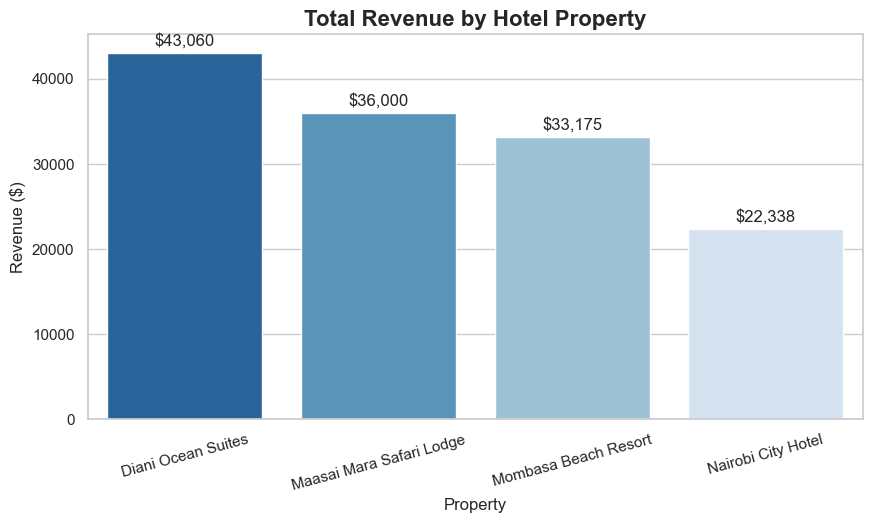

In [8]:
plt.figure(figsize=(10, 5))
rev_prop = df_dw.groupby('property_name')['revenue'].sum().sort_values(ascending=False)
ax = sns.barplot(x=rev_prop.index, y=rev_prop.values, palette="Blues_r")

plt.title('Total Revenue by Hotel Property', fontsize=16, fontweight='bold')
plt.xlabel('Property', fontsize=12)
plt.ylabel('Revenue ($)', fontsize=12)
plt.xticks(rotation=15)

# Add value labels on top of bars
for p in ax.patches:
    ax.annotate(f'${p.get_height():,.0f}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), textcoords='offset points')
plt.show()

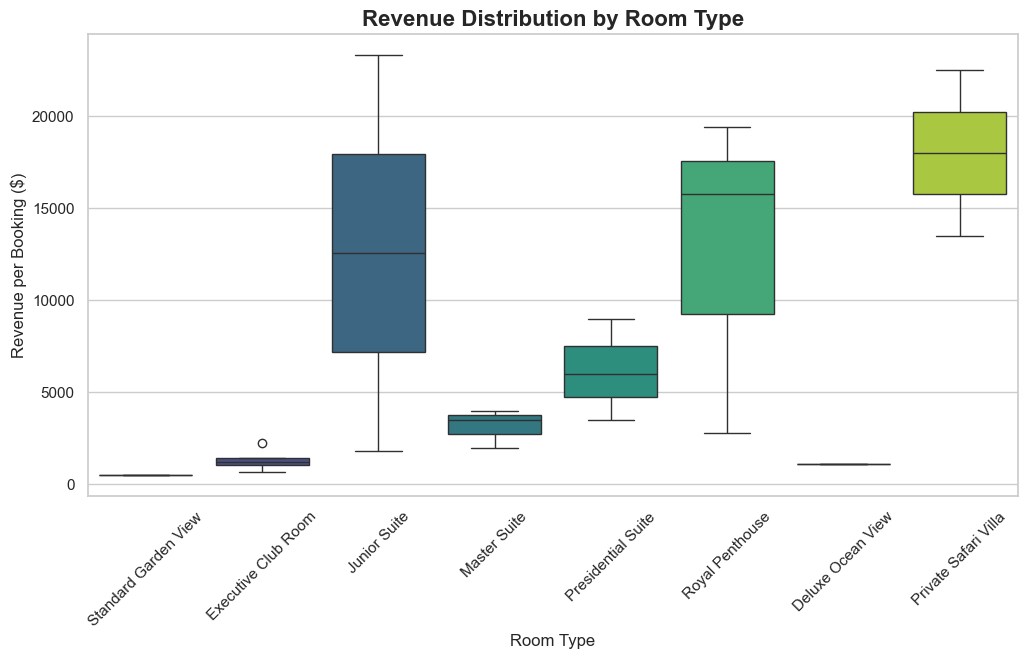

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_dw, x='room_type', y='revenue', palette="viridis")
plt.title('Revenue Distribution by Room Type', fontsize=16, fontweight='bold')
plt.xlabel('Room Type', fontsize=12)
plt.ylabel('Revenue per Booking ($)', fontsize=12)
plt.xticks(rotation=45)
plt.show()

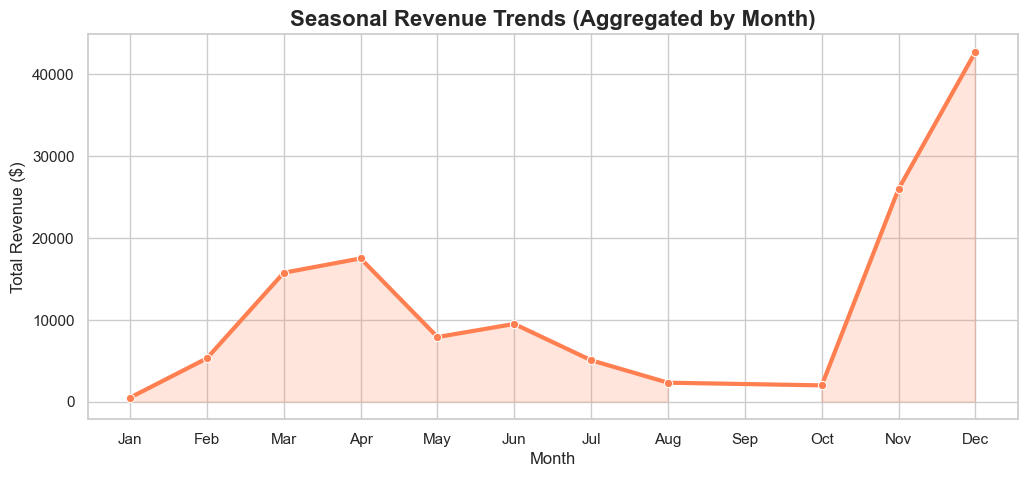

In [10]:
plt.figure(figsize=(12, 5))
monthly_rev = df_dw.groupby('month_name')['revenue'].sum().reindex(
    ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
)
sns.lineplot(x=monthly_rev.index, y=monthly_rev.values, marker='o', linewidth=3, color='coral')

plt.title('Seasonal Revenue Trends (Aggregated by Month)', fontsize=16, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.fill_between(monthly_rev.index, monthly_rev.values, alpha=0.2, color='coral')
plt.show()

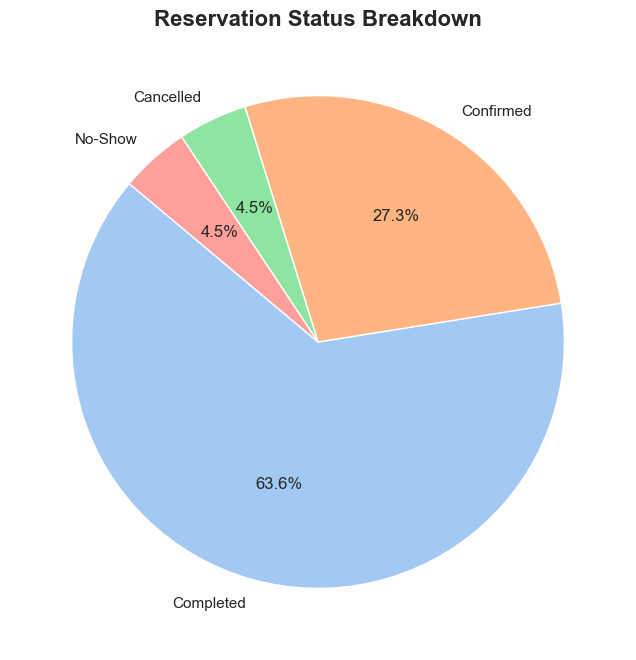

In [11]:
plt.figure(figsize=(8, 8))
status_counts = df_oltp['booking_status'].value_counts()
plt.pie(status_counts.values, labels=status_counts.index, autopct='%1.1f%%', 
        startangle=140, colors=sns.color_palette("pastel"))
plt.title('Reservation Status Breakdown', fontsize=16, fontweight='bold')
plt.show()

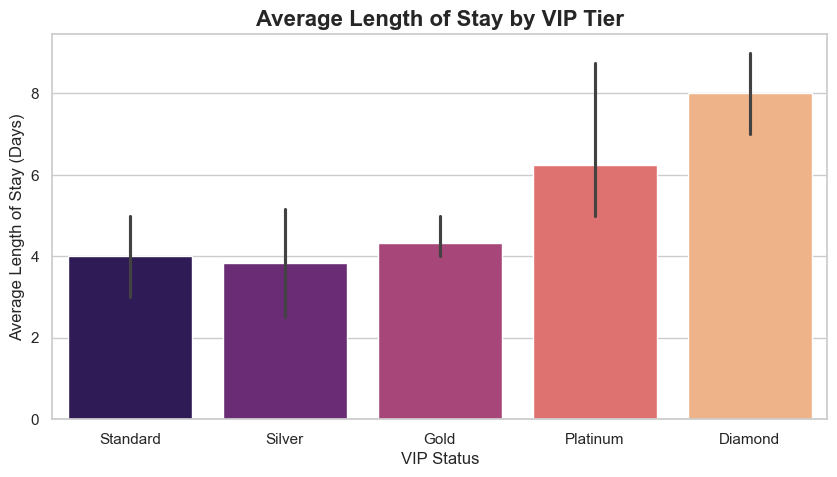

In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_oltp, x='vip_status', y='length_of_stay', 
            order=['Standard', 'Silver', 'Gold', 'Platinum', 'Diamond'], palette="magma")
plt.title('Average Length of Stay by VIP Tier', fontsize=16, fontweight='bold')
plt.xlabel('VIP Status', fontsize=12)
plt.ylabel('Average Length of Stay (Days)', fontsize=12)
plt.show()

##  Key Findings & Business Recommendations

Based on the Exploratory Data Analysis (EDA) conducted above, we have derived the following actionable insights:

1. **Property Performance (Visualization 1):** 
   * The hotel chain has clear flagship locations driving the majority of the revenue. 
   * *Recommendation:* Allocate marketing budgets proportionally to the top-performing properties.

2. **Room Profitability (Visualization 2):** 
   * While standard rooms have the highest volume, premium suites (Master Suite, Royal Penthouse) generate massive revenue spikes per individual booking.
   * *Recommendation:* Implement an "upsell" strategy at check-in to move guests from Standard to premium categories.

3. **Seasonality (Visualization 3):**
   * Revenue peaks significantly in December (driven by the Christmas Rate Plan multiplier) and mid-year. 
   * *Recommendation:* Enforce strict non-refundable policies during peak months to prevent cancellations and maximize yield.

4. **Guest Loyalty (Visualization 5):**
   * High-tier guests (Diamond/Platinum) tend to have longer stays.
   * *Recommendation:* Offer exclusive packages to convert Standard/Silver guests into long-stay loyalists.